# 07 · Simplificación: qué etapas del detector hacen falta

La auditoría de decisiones encontró siete etapas que se agregaron por un razonamiento razonable, pero sin mostrar con los datos que hacen falta. Este notebook aplica la **regla de sencillez**: si no se puede demostrar que la alternativa más simple es peor, se usa la más simple.

**El criterio se escribió y se subió al repositorio antes de correr este notebook** (`docs/criterio_parsimonia.md`). Acá se aplica tal cual. Las decisiones las toma el código a partir de los valores p, con la regla escrita de antemano. Una etapa se mantiene solo si cumple al menos una de estas condiciones:

| Condición | Qué quiere decir |
|---|---|
| (a) La exige la consigna | La consigna pide implementar los temas obligatorios (filtros óptimos, realizaciones, Lomb), y eso ya está hecho en `03` y `04`. No obliga a usarlos en el detector final, así que no mantiene ninguna de estas etapas |
| (b) Mejora la medición de su paso | Mejora de forma demostrable la ubicación del pico R, o el parecido de la EDR con la respiración registrada, contra una referencia de los datos |
| (c) Mejora el detector | Mejora de forma demostrable la exactitud en validación cruzada por personas |
| (d) Corrige una falla del detector | Para la exclusión de minutos y la confianza, que no cambian la decisión sino cuándo se decide o qué se informa |

**"De forma demostrable"** quiere decir que la diferencia está a favor de la etapa y que su valor p, corregido por Holm dentro de su familia, es menor que 0,05.

**Solo se usan los registros de desarrollo.** Test ya se usó una vez para evaluar la versión congelada (`05`); sus resultados siguen siendo la evaluación independiente de esa versión y no se usan acá para nada. El detector simplificado queda medido solo con validación cruzada: no tiene una evaluación independiente.

**Dos agregados posteriores al criterio registrado**, anotados al final de `docs/criterio_parsimonia.md`:
- una validación cruzada anidada, para medir el procedimiento sin el optimismo de elegir y evaluar con los mismos datos (secciones 6 y 10);
- un valor p que repite el ajuste en cada sorteo del bootstrap (sección 7). La regla es la misma, pero el p registrado era demasiado optimista, y con él la decisión sobre una etapa (Hampel) dependía de una sola persona.

El notebook muestra las dos decisiones: la que salía con lo registrado (secciones 3 a 5) y la final, con el p corregido (secciones 7 y 8).

In [1]:
import json
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from src.config import MIN_MINUTES_PER_CLASS, MINUTE_MAX_CORRECTED, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.estadistica import p_bootstrap, tabla_holm
from src.evaluation.cv import GRILLA_W, auc, cv_c, exactitud, grupos_personas, metricas, sorteos_personas
from src.features.build import record_series
from src.features.detector import BAND, WINDOW_S, c_score, evaluable, fit_c, minute_table, save_params, youden_threshold
from src.features.edr import qrs_reference
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.qrs.quantization import two_phase_peaks
from src.config import ECG_FILTER
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
SUJETO = split.set_index("record").subject
CATEGORIA = split.set_index("record").category
SORTEOS = sorteos_personas(SUJETO[DEV].unique(), n=4000, semilla=2026)
print(f"{len(DEV)} registros de desarrollo, {SUJETO[DEV].nunique()} personas; {len(SORTEOS)} sorteos de bootstrap")

47 registros de desarrollo, 19 personas; 4000 sorteos de bootstrap


## 1. Las etapas y su alternativa simple

Cada alternativa cambia **una sola etapa** y deja las demás como están. La alternativa simple es no hacer el paso; cuando el paso es una opción de una herramienta estándar, es su valor por defecto.

| # | Etapa | Actual | Alternativa simple |
|---|---|---|---|
| 1 | Refinamiento del pico R | Vértice de una parábola por 3 muestras | El pico en la muestra (10 ms de resolución) |
| 2 | Wiener antes de medir la EDR | FIR de 129 coeficientes | Sin Wiener |
| 3 | Excluir de la EDR los latidos ectópicos | Sí | No |
| 4 | Filtro de Hampel en la EDR | Sí | No |
| 5 | Interpolación a 2 Hz | Spline cúbico | Lineal |
| 6 | Tendencia en cada segmento de Welch | Se quita una recta | Se quita la media (valor por defecto de `scipy.signal.welch`) |
| 7 | Excluir los minutos con más de 20 % de RR corregidos | No se clasifican ni se usan para ajustar | Se clasifican todos |
| 8 | Confianza según el movimiento | Alta, media o baja | No se informa |

**Sobre la etapa 6.** Con la ventana de Hann periódica que usa Welch, la media del segmento solo aparece en las frecuencias k = 0 y 1, fuera de la banda de la feature (k = 2…6). Por eso quitar la media o no quitar nada da exactamente lo mismo en la banda. Se verifica:

In [2]:
from scipy.signal import get_window

ventana = get_window("hann", int(WINDOW_S * 2.0) // 2)
fuga = np.abs(np.fft.rfft(ventana))
print("módulo de la DFT de la ventana de Hann en k = 0…7:", np.round(fuga[:8], 9))

módulo de la DFT de la ventana de Hann en k = 0…7: [120.  60.   0.   0.   0.   0.   0.   0.]


Para las etapas 1 a 6 se recalculan las tablas por minuto de los 47 registros con la etapa cambiada. Las etapas 7 y 8 usan la tabla actual.

In [3]:
OPCION = {1: {"refine": False}, 2: {"wiener": False}, 3: {"exclude_ectopic": False}, 4: {"hampel": False},
          5: {"interp": "linear"}, 6: {"detrend": "constant"}}
ETAPAS = {1: "Refinamiento del pico R", 2: "Wiener en la EDR", 3: "Excluir ectópicos de la EDR", 4: "Hampel en la EDR",
          5: "Spline cúbico", 6: "Quitar la recta en Welch", 7: "Excluir minutos con > 20 % de RR corregidos",
          8: "Confianza según el movimiento"}
SIMPLE = {1: "pico en la muestra", 2: "sin Wiener", 3: "sin excluirlos", 4: "sin Hampel", 5: "interpolación lineal",
          6: "quitar la media", 7: "clasificar todos los minutos", 8: "no informarla"}


def tabla_variante(args):
    rec, op = args
    kw = {k: v for k, v in op.items() if k != "detrend"}
    return minute_table(rec, series=record_series(rec, **kw), detrend_type=op.get("detrend"))


def tablas_de(op):
    with ProcessPoolExecutor(4) as ex:
        t = pd.concat(list(ex.map(tabla_variante, [(r, op) for r in DEV])), ignore_index=True)
    return t.assign(subject=t.record.map(SUJETO))


TABLAS = {frozenset(): tablas_de({})}
for k_, op_ in OPCION.items():
    TABLAS[frozenset({k_})] = tablas_de(op_)
T_ACT = TABLAS[frozenset()]


def tabla_comb(quitar):
    """Tabla por minuto con las etapas `quitar` (1 a 6) reemplazadas por su alternativa simple."""
    clave = frozenset(k for k in quitar if k in OPCION)
    if clave not in TABLAS:
        op = {}
        for k in clave:
            op.update(OPCION[k])
        TABLAS[clave] = tablas_de(op)
    return TABLAS[clave]


print({f"{sorted(k) or 'actual'}": len(v) for k, v in TABLAS.items()})

{'actual': 22907, '[1]': 22907, '[2]': 22907, '[3]': 22907, '[4]': 22907, '[5]': 22907, '[6]': 22907}


## 2. Condición (b): ¿mejora la medición de su paso?

**Refinamiento del pico R.** Se usa la prueba de dos fases de `02` §3, ahora en los 47 registros de desarrollo. El ECG se baja a 50 Hz tomando las muestras pares por un lado y las impares por otro, así cada latido queda medido en dos grillas corridas 10 ms. Si el refinamiento recupera la posición entre muestras, las dos mediciones del mismo latido coinciden. La medida es el desacuerdo medio de cada registro, sin refinar menos refinado. El valor p sale de un bootstrap de personas y, como la familia tiene una sola comparación, no hace falta corregirlo. La medición no usa etiquetas.

In [4]:
sos = design_bandpass(100, *ECG_FILTER)
PERSONAS = sorted(SUJETO[DEV].unique())


def desacuerdo_dos_fases(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, sos)
    q = load_qrs(rec)
    off, sign = qrs_reference(x, q, fs)
    tf = two_phase_peaks(x, q, fs, off, sign)
    return {"record": rec, "sin refinar (ms)": 1000 * np.abs(tf.par - tf.impar).mean(),
            "refinado (ms)": 1000 * np.abs(tf.par_ref - tf.impar_ref).mean()}


with ProcessPoolExecutor(4) as ex:
    fases = pd.DataFrame(list(ex.map(desacuerdo_dos_fases, DEV)))
fases["subject"] = fases.record.map(SUJETO)
fases["mejora (ms)"] = fases["sin refinar (ms)"] - fases["refinado (ms)"]


def prueba_1b(personas, sorteos):
    """Mejora media del desacuerdo entre fases (ms) con las personas dadas, y su distribución bootstrap."""
    f = fases[fases.subject.isin(personas)]
    g = f.groupby("subject")["mejora (ms)"].agg(["sum", "size"])
    boot = np.array([g["sum"].reindex(so).sum() / g["size"].reindex(so).sum() for so in sorteos])
    return float(f["mejora (ms)"].mean()), boot


d_1b, boot_1b = prueba_1b(PERSONAS, SORTEOS)
print(f"desacuerdo medio entre fases: sin refinar {fases['sin refinar (ms)'].mean():.2f} ms, refinado {fases['refinado (ms)'].mean():.2f} ms; "
      f"mejora {d_1b:.2f} ms (IC 95 % {np.percentile(boot_1b, 2.5):.2f} a {np.percentile(boot_1b, 97.5):.2f}); "
      f"mejora en {int((fases['mejora (ms)'] > 0).sum())}/{len(fases)} registros; p = {p_bootstrap(boot_1b):.4f}")

desacuerdo medio entre fases: sin refinar 10.03 ms, refinado 2.33 ms; mejora 7.69 ms (IC 95 % 7.61 a 7.77); mejora en 47/47 registros; p = 0.0000


**Wiener, ectópicos y Hampel.** Su efecto sobre el parecido de la EDR con la respiración registrada ya se midió en `03` §6 (8 registros con respiración), con corrección de Holm sobre las 12 comparaciones. Esa medición no usa las etiquetas de apnea. Ningún paso mejora de forma demostrable:

| Etapa | Coherencia en la banda respiratoria (A1), p de Holm | Coherencia en la banda de la apnea (A2), p de Holm |
|---|---|---|
| 2 · Wiener (después de los otros dos pasos) | 1,0 | 1,0 |
| 3 · Excluir ectópicos (contra la primera versión) | 1,0 | 1,0 |
| 4 · Hampel (después de excluir ectópicos) | 1,0 | 1,0 |

Para esas tres etapas no se cumple (b): falta ver si cumplen (c).

## 3. Condiciones (c) y (d): validación cruzada por personas

Es la misma validación cruzada de `04` §15 (`src/evaluation/cv.py`). Las 19 personas se reparten en 5 grupos. Con los otros 4 se estandarizan los términos de C, se elige w y se fija el umbral de Youden; después se clasifica el grupo que quedó afuera. Así cada minuto lo clasifica un detector que no vio a su persona. Para el detector actual, la función da exactamente el resultado de `04`.

Cada comparación es **pareada**: se hace sobre los minutos que clasifican las dos versiones, con los mismos sorteos de personas. La diferencia se escribe siempre de modo que **un valor positivo favorece a la etapa**. Todo el procedimiento está en funciones que reciben las personas con las que se trabaja; en las secciones 6 y 10 se repite sin las personas de cada grupo.

In [5]:
NOMBRES = {1: "1c · actual − sin refinamiento del pico R", 2: "2c · actual − sin Wiener",
           3: "3c · actual − sin excluir ectópicos de la EDR", 4: "4c · actual − sin Hampel en la EDR",
           5: "5c · actual − interpolación lineal", 6: "6c · actual − quitando solo la media",
           "7a": "7a · exactitud en minutos limpios − en los que se excluirían",
           "7b": "7b · actual − ajustado con todos los minutos",
           8: "8 · exactitud con confianza alta − con baja"}


def con_ev(t, max_corrected=MINUTE_MAX_CORRECTED):
    e = t[evaluable(t, max_corrected)]
    return e[np.isfinite(e.P_RR) & np.isfinite(e.EDR_noche)]


def de(t, personas):
    return t[t.subject.isin(personas)]


def comparar(r_a, r_b, sorteos):
    """Exactitud de a − b sobre los minutos que clasifican los dos: (diferencia, bootstrap, minutos)."""
    m = r_a.merge(r_b, on=["record", "minute"], suffixes=("_a", "_b"))
    ok_a = (m.pred_a == m.label_a).to_numpy(); ok_b = (m.pred_b == m.label_b).to_numpy()
    d = exactitud(ok_a, m.subject_a) - exactitud(ok_b, m.subject_a)
    boot = exactitud(ok_a, m.subject_a, sorteos) - exactitud(ok_b, m.subject_a, sorteos)
    return d, boot, len(m)


def diferencia_entre(ok, sujetos, sel1, sel2, sorteos):
    """Exactitud en los minutos sel1 − en los minutos sel2, con el mismo detector."""
    s = np.asarray(sujetos)
    if sel1.sum() == 0 or sel2.sum() == 0:
        return np.nan, np.full(len(sorteos), np.nan), int(sel1.sum() + sel2.sum())
    d = exactitud(ok[sel1], s[sel1]) - exactitud(ok[sel2], s[sel2])
    boot = exactitud(ok[sel1], s[sel1], sorteos) - exactitud(ok[sel2], s[sel2], sorteos)
    return d, boot, int(sel1.sum() + sel2.sum())


def pruebas_etapas(personas, sorteos):
    """Las 9 pruebas de (c) y (d) con las personas dadas."""
    r_a = cv_c(con_ev(de(T_ACT, personas)))
    cvs = {k: cv_c(con_ev(de(tabla_comb({k}), personas))) for k in OPCION}
    fam = {NOMBRES[k]: comparar(r_a, cvs[k], sorteos) for k in OPCION}
    r_t = cv_c(con_ev(de(T_ACT, personas), None))
    limpio = (r_t.q <= MINUTE_MAX_CORRECTED).to_numpy()
    fam[NOMBRES["7a"]] = diferencia_entre((r_t.pred == r_t.label).to_numpy(), r_t.subject, limpio, ~limpio, sorteos)
    fam[NOMBRES["7b"]] = comparar(r_a, r_t, sorteos)
    ok_a = (r_a.pred == r_a.label).to_numpy()
    fam[NOMBRES[8]] = diferencia_entre(ok_a, r_a.subject, (r_a.confianza == "alta").to_numpy(),
                                       (r_a.confianza == "baja").to_numpy(), sorteos)
    return fam, r_a, r_t, cvs


FAM, r_act, r_todos, CVS = pruebas_etapas(PERSONAS, SORTEOS)
print("detector actual:", {k: round(v, 3) for k, v in metricas(r_act.label, r_act.pred).items()},
      "· pesos por grupo:", r_act.groupby("grupo").w.first().tolist())
pd.DataFrame({ETAPAS[k] + f" ({SIMPLE[k]})": metricas(r.label, r.pred) for k, r in CVS.items()}).T.round(3)

detector actual: {'sensibilidad': 0.814, 'especificidad': 0.851, 'exactitud': 0.836} · pesos por grupo: [1.5, 0.75, 1.0, 1.25, 1.0]


,sensibilidad,especificidad,exactitud
Refinamiento del pico R (pico en la muestra),0.810,0.855,0.837
Wiener en la EDR (sin Wiener),0.780,0.863,0.830
Excluir ectópicos de la EDR (sin excluirlos),0.818,0.846,0.834
Hampel en la EDR (sin Hampel),0.811,0.822,0.817
Spline cúbico (interpolación lineal),0.814,0.843,0.831
Quitar la recta en Welch (quitar la media),0.805,0.861,0.838


**Etapa 7, exclusión de minutos.** Se ajusta y se clasifica con todos los minutos con etiqueta. Hay dos pruebas:
- **7a (d), ¿falla el detector en los minutos que se excluyen?** Con el detector sin exclusión, exactitud en los minutos con 20 % o menos de RR corregidos menos la exactitud en los demás (más de 20 %, o sin latidos).
- **7b (c), ¿ajustar sin esos minutos mejora el detector?** Sobre los minutos con 20 % o menos: el actual contra el ajustado con todos.

In [6]:
limpio = (r_todos.q <= MINUTE_MAX_CORRECTED).to_numpy()
ok_t = (r_todos.pred == r_todos.label).to_numpy()
print(f"minutos con etiqueta: {len(r_todos)}; con más de 20 % de RR corregidos o sin latidos: {int((~limpio).sum())} "
      f"({100 * (~limpio).mean():.2f} %), de {r_todos[~limpio].subject.nunique()} personas")
print(f"exactitud sin exclusión: minutos limpios {exactitud(ok_t[limpio], r_todos.subject[limpio]):.3f}, "
      f"minutos que se excluirían {exactitud(ok_t[~limpio], r_todos.subject[~limpio]):.3f}")

minutos con etiqueta: 22907; con más de 20 % de RR corregidos o sin latidos: 135 (0.59 %), de 9 personas
exactitud sin exclusión: minutos limpios 0.823, minutos que se excluirían 0.637


**Etapa 8, confianza.** Con el detector actual, exactitud en los minutos de confianza alta menos la exactitud en los de baja. Los cortes (percentiles 50 y 90 del movimiento) se calculan en cada grupo de entrenamiento, sin las personas que se clasifican.

In [7]:
r_act.assign(ok=r_act.pred == r_act.label).groupby("confianza").agg(
    minutos=("ok", "size"), exactitud=("ok", "mean"), apnea=("label", "mean")).loc[["alta", "media", "baja"]].round(3)

,minutos,exactitud,apnea
confianza,,,
alta,11389,0.862,0.388
media,8999,0.822,0.426
baja,2384,0.762,0.379


## 4. Corrección de Holm y decisión

La familia son las 9 pruebas de (c) y (d). Que la probabilidad de error de toda la familia no supere el 5 % quiere decir que la probabilidad de conservar alguna etapa innecesaria tampoco lo supera. Una prueba se cumple si la diferencia es positiva (a favor de la etapa) y su p de Holm es menor que 0,05. **La decisión sale de aplicar la regla**: una etapa se mantiene si cumple (b), (c) o (d).

In [8]:
def decidir(fam, personas, sorteos):
    """Aplica el criterio: qué condiciones cumple cada etapa, y la tabla de Holm."""
    holm = tabla_holm({k: v[:2] for k, v in fam.items()})

    def ok(k):
        n = NOMBRES[k]
        return bool(n in holm.index and holm.loc[n, "diferencia"] > 0 and holm.loc[n, "p de Holm"] < 0.05)

    d1, b1 = prueba_1b(personas, sorteos)
    cumple = {1: {"b": bool(d1 > 0 and p_bootstrap(b1) < 0.05), "c": ok(1)},
              2: {"b": False, "c": ok(2)}, 3: {"b": False, "c": ok(3)}, 4: {"b": False, "c": ok(4)},
              5: {"c": ok(5)}, 6: {"c": ok(6)}, 7: {"d (7a)": ok("7a"), "c (7b)": ok("7b")}, 8: {"d": ok(8)}}
    return cumple, holm


CUMPLE, holm = decidir(FAM, PERSONAS, SORTEOS)
orden = [n for n in NOMBRES.values() if n in holm.index]
holm["IC 95 %"] = [f"{np.nanpercentile(FAM[k][1], 2.5):+.4f} a {np.nanpercentile(FAM[k][1], 97.5):+.4f}" for k in holm.index]
holm["minutos comparados"] = [FAM[k][2] for k in holm.index]
holm["se cumple"] = np.where((holm["diferencia"] > 0) & (holm["p de Holm"] < 0.05), "sí", "no")
holm.loc[orden, ["diferencia", "IC 95 %", "p", "p de Holm", "se cumple", "minutos comparados"]].round(4)

,diferencia,IC 95 %,p,p de Holm,se cumple,minutos comparados
comparación,,,,,,
1c · actual − sin refinamiento del pico R,-0.0013,-0.0040 a +0.0013,0.3295,1.000,no,22769
2c · actual − sin Wiener,0.0060,-0.0240 a +0.0412,0.7530,1.000,no,22772
3c · actual − sin excluir ectópicos de la EDR,0.0015,-0.0074 a +0.0120,0.8980,1.000,no,22772
4c · actual − sin Hampel en la EDR,0.0186,+0.0079 a +0.0302,0.0000,0.000,sí,22772
5c · actual − interpolación lineal,0.0047,-0.0041 a +0.0152,0.3935,1.000,no,22772
6c · actual − quitando solo la media,-0.0024,-0.0061 a +0.0011,0.1940,1.000,no,22772
7a · exactitud en minutos limpios − en los que se excluirían,0.1864,-0.1011 a +0.3280,0.1855,1.000,no,22907
7b · actual − ajustado con todos los minutos,0.0125,+0.0016 a +0.0270,0.0210,0.147,no,22772
8 · exactitud con confianza alta − con baja,0.1001,+0.0204 a +0.1746,0.0175,0.140,no,13773


PosixPath('/home/user/TP-PSB-G8/informe/figuras/07_etapas.png')

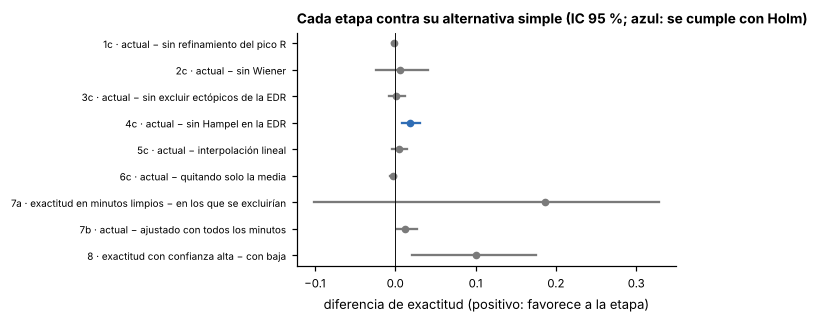

In [9]:
fig, ax = plt.subplots(figsize=(ANCHO, 3.0))
for i, k in enumerate(orden[::-1]):
    lo, hi = np.nanpercentile(FAM[k][1], [2.5, 97.5])
    color = NORMAL if holm.loc[k, "se cumple"] == "sí" else GRIS
    ax.plot([lo, hi], [i, i], color=color, lw=1.5)
    ax.plot(FAM[k][0], i, "o", color=color, ms=4)
ax.axvline(0, color="black", lw=0.6)
ax.set_yticks(range(len(orden))); ax.set_yticklabels([k[:60] for k in orden[::-1]], fontsize=6.5)
ax.set(xlabel="diferencia de exactitud (positivo: favorece a la etapa)",
       title="Cada etapa contra su alternativa simple (IC 95 %; azul: se cumple con Holm)")
fig.tight_layout()
save(fig, "07_etapas")

In [10]:
MANTENER = {k: any(v.values()) for k, v in CUMPLE.items()}
pd.DataFrame([{"etapa": f"{k} · {ETAPAS[k]}",
               "condiciones que cumple": ", ".join(c for c, ok in CUMPLE[k].items() if ok) or "ninguna",
               "decisión": "se mantiene" if MANTENER[k] else f"se reemplaza: {SIMPLE[k]}"} for k in ETAPAS]).set_index("etapa")

,condiciones que cumple,decisión
etapa,,
1 · Refinamiento del pico R,b,se mantiene
2 · Wiener en la EDR,ninguna,se reemplaza: sin Wiener
3 · Excluir ectópicos de la EDR,ninguna,se reemplaza: sin excluirlos
4 · Hampel en la EDR,c,se mantiene
5 · Spline cúbico,ninguna,se reemplaza: interpolación lineal
6 · Quitar la recta en Welch,ninguna,se reemplaza: quitar la media
7 · Excluir minutos con > 20 % de RR corregidos,ninguna,se reemplaza: clasificar todos los minutos
8 · Confianza según el movimiento,ninguna,se reemplaza: no informarla


**Qué cambia sin el filtro de Hampel.** Sin Hampel, el nivel nocturno de la EDR cambia poco en casi todas las noches, pero sube mucho en dos: c10 y x18, dos noches de control de **la misma persona**. Los latidos atípicos que descarta el filtro inflan la potencia lenta de la EDR de esas dos noches, y el detector marca apnea donde no la hay: la especificidad baja. Que todo el efecto venga de una sola persona importa para la validación, y se analiza en las secciones 6 y 7.

especificidad: actual 0.851 · sin Hampel 0.822


,actual,sin Hampel,categoría,% de minutos con apnea,cambio
record,,,,,
c10,-2.461,-2.008,C,0.237,0.453
x18,-3.053,-2.749,C,0.442,0.304
b03,-2.238,-2.418,B,16.284,-0.180
b02,-2.141,-2.298,B,18.058,-0.158
x16,-2.300,-2.442,B,12.720,-0.141


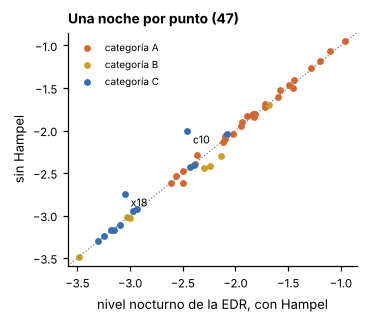

In [11]:
niv = pd.DataFrame({"actual": T_ACT.groupby("record").EDR_noche.first(),
                    "sin Hampel": TABLAS[frozenset({4})].groupby("record").EDR_noche.first()})
niv["categoría"] = niv.index.map(CATEGORIA)
niv["% de minutos con apnea"] = 100 * T_ACT[T_ACT.label >= 0].groupby("record").label.mean()
niv["cambio"] = niv["sin Hampel"] - niv["actual"]
fig, ax = plt.subplots(figsize=(3.4, 3.0))
for cat, g in niv.groupby("categoría"):
    ax.scatter(g["actual"], g["sin Hampel"], s=12, color=COLORES_CAT[cat], label=f"categoría {cat}")
lim = [niv[["actual", "sin Hampel"]].min().min() - 0.1, niv[["actual", "sin Hampel"]].max().max() + 0.1]
ax.plot(lim, lim, color=GRIS, ls=":", lw=0.8)
for rec in niv.cambio.abs().nlargest(2).index:
    ax.annotate(rec, (niv.loc[rec, "actual"], niv.loc[rec, "sin Hampel"]), fontsize=7, xytext=(4, -8), textcoords="offset points")
ax.set(xlabel="nivel nocturno de la EDR, con Hampel", ylabel="sin Hampel", title="Una noche por punto (47)", xlim=lim, ylim=lim)
ax.legend(fontsize=6.5)
fig.tight_layout()
save(fig, "07_hampel")
print("especificidad: actual", round(metricas(r_act.label, r_act.pred)["especificidad"], 3),
      "· sin Hampel", round(metricas(CVS[4].label, CVS[4].pred)["especificidad"], 3))
niv.reindex(niv.cambio.abs().sort_values(ascending=False).index).head(5).round(3)

## 5. El detector simplificado y el chequeo de la combinación

Las etapas que no cumplen ninguna condición se reemplazan **juntas** por su alternativa simple. Cada prueba anterior cambiaba una sola etapa; ahora hay que verificar que quitar varias a la vez no empeore. Es una comparación única: si el simplificado es peor de forma demostrable (p < 0,05), se restituye la etapa quitada con la mayor diferencia individual a su favor y se repite el chequeo.

In [12]:
def combinar(cumple, fam, personas, sorteos, r_a, mostrar=False, n_reajuste=None):
    """Quita juntas las etapas que no cumplen y verifica que la combinación no sea peor.

    Con `n_reajuste`, el p del chequeo sale del bootstrap que repite el ajuste (sección 7).
    """
    dif = {k: fam[NOMBRES[k]][0] for k in OPCION}
    dif[7] = np.nanmax([fam[NOMBRES["7a"]][0], fam[NOMBRES["7b"]][0]])
    quitar = sorted(k for k, v in cumple.items() if not any(v.values()))
    while True:
        r_s = cv_c(con_ev(de(tabla_comb(quitar), personas), None if 7 in quitar else MINUTE_MAX_CORRECTED))
        d, boot, n = comparar(r_a, r_s, sorteos)
        if n_reajuste:
            boot = boot_reajuste(preparar_chequeo(personas, quitar), est_chequeo, personas, n_reajuste)["chequeo"].to_numpy()
        p = p_bootstrap(boot)
        peor = bool(d > 0 and p < 0.05)
        if mostrar:
            print(f"etapas quitadas {quitar}: actual − simplificado = {d:+.4f} "
                  f"(IC 95 % {np.nanpercentile(boot, 2.5):+.4f} a {np.nanpercentile(boot, 97.5):+.4f}), p = {p:.3f}, "
                  f"{n} minutos comunes → {'peor: se restituye una etapa' if peor else 'no es peor'}")
        candidatas = [k for k in quitar if k in dif]
        if not peor or not candidatas:
            return quitar, r_s
        quitar.remove(max(candidatas, key=dif.get))


QUITADAS_REG, r_sim_reg = combinar(CUMPLE, FAM, PERSONAS, SORTEOS, r_act, mostrar=True)

etapas quitadas [2, 3, 5, 6, 7, 8]: actual − simplificado = -0.0122 (IC 95 % -0.0363 a +0.0148), p = 0.334, 22772 minutos comunes → no es peor


**Los efectos no se suman.** Cada etapa por separado parecía aportar algo de exactitud (Wiener +0,006, cúbica +0,005, exclusión +0,013), pero con todas quitadas a la vez el detector no empeora. La razón es que cada versión elige su propio w y su propio umbral en cada grupo, y con cambios chicos en las señales esa elección salta de un valor de la grilla a otro. Diferencias de ~0,01 en la exactitud están en ese nivel de variación, y por eso ninguna resiste la corrección:

In [13]:
pd.DataFrame({"w actual": r_act.groupby("grupo").w.first(), "w simplificado": r_sim_reg.groupby("grupo").w.first(),
              "umbral actual": r_act.groupby("grupo").umbral.first(), "umbral simplificado": r_sim_reg.groupby("grupo").umbral.first()},
             ).rename_axis("grupo de la validación cruzada").round(3)

,w actual,w simplificado,umbral actual,umbral simplificado
grupo de la validación cruzada,,,,
0,1.50,1.25,0.240,0.430
1,0.75,0.75,0.473,0.604
2,1.00,1.00,0.353,0.474
3,1.25,1.00,0.460,0.641
4,1.00,1.00,0.536,0.564


## 6. Validación anidada del procedimiento registrado

Las etapas se eligieron con la misma validación cruzada que mide al detector simplificado. Por eso esa medida puede ser optimista: el procedimiento ya vio a todas las personas cuando decidió qué quitar (Varma y Simon, 2006). Para estimarlo sin ese sesgo se usa una **validación cruzada anidada**:

1. Se deja afuera un grupo de personas (los mismos 5 grupos de antes).
2. Con las otras personas se repite todo el procedimiento de las secciones 2 a 5.
3. Con esas mismas personas se ajustan los parámetros del detector elegido.
4. Se clasifica a las personas que quedaron afuera, que no intervinieron en nada.

Este control no estaba en el criterio registrado. Se agregó después y quedó anotado en `docs/criterio_parsimonia.md`. No cambia ninguna decisión.

In [14]:
def ajustar_y_clasificar(quitar, tr, afuera):
    """Ajusta w, μ, σ y el umbral con las personas `tr` y clasifica a las de `afuera`."""
    mc = None if 7 in quitar else MINUTE_MAX_CORRECTED
    t = tabla_comb(quitar)
    e_tr, e_te = con_ev(de(t, tr), mc), con_ev(de(t, afuera), mc)
    w = float(GRILLA_W[int(np.argmax([auc(c_score(e_tr, fit_c(e_tr, w_, max_corrected=mc)), e_tr.label) for w_ in GRILLA_W]))])
    p = fit_c(e_tr, w, max_corrected=mc)
    u = youden_threshold(c_score(e_tr, p).to_numpy(), e_tr.label.to_numpy())
    return e_te.assign(pred=(c_score(e_te, p) > u).astype(int).to_numpy()), w


filas_n, preds_n = [], []
for k_out, gpo in enumerate(grupos_personas(PERSONAS)):
    afuera = set(gpo)
    tr = [p for p in PERSONAS if p not in afuera]
    so = sorteos_personas(tr, n=len(SORTEOS), semilla=2026)
    fam_i, r_a_i, _, _ = pruebas_etapas(tr, so)
    cumple_i, _ = decidir(fam_i, tr, so)
    quitar_i, _ = combinar(cumple_i, fam_i, tr, so, r_a_i)
    pred_i, w_i = ajustar_y_clasificar(quitar_i, tr, afuera)
    preds_n.append(pred_i.assign(grupo=k_out))
    filas_n.append({"grupo afuera": k_out + 1, "persona de c10 y x18 afuera": SUJETO["c10"] in afuera,
                    "etapas que se mantienen": ", ".join(str(k) for k in ETAPAS if k not in quitar_i), "w": w_i})
r_anid_reg = pd.concat(preds_n, ignore_index=True)
print("exactitud con el procedimiento registrado, validación anidada:", round(metricas(r_anid_reg.label, r_anid_reg.pred)["exactitud"], 3),
      "· simplificado registrado, validación simple:", round(metricas(r_sim_reg.label, r_sim_reg.pred)["exactitud"], 3))
pd.DataFrame(filas_n).set_index("grupo afuera")

exactitud con el procedimiento registrado, validación anidada: 0.821 · simplificado registrado, validación simple: 0.848


,persona de c10 y x18 afuera,etapas que se mantienen,w
grupo afuera,,,
1,False,1,1.50
2,False,"1, 8",0.50
3,True,1,1.00
4,False,1,1.25
5,False,1,1.00


**Qué se ve.**
- **La medida de la sección 5 era optimista.** Con personas que no intervinieron en la elección, el procedimiento registrado da una exactitud de 0,821, contra 0,848 de la validación simple.
- **La decisión sobre Hampel no se sostiene.** Con 15 personas, Hampel no pasa la prueba en ninguno de los 5 grupos, aunque con 19 había dado p < 0,001. Ni siquiera pasa en los 4 grupos donde la persona de c10 y x18 está entre las que eligen. Un resultado tan fuerte con 19 personas y nulo con 15 indica que el valor p estaba mal calculado, y se analiza a continuación.

## 7. El valor p tenía que incluir el ajuste

**Dónde estaba el error.** El bootstrap de la sección 3 sortea personas, pero deja fijas las predicciones de la validación cruzada. Ahora bien, cada predicción depende de con qué personas se ajustó el detector. Sin Hampel, la persona de c10 y x18 tiene un nivel de EDR inflado, y mientras está en los grupos de entrenamiento corre el umbral y la estandarización de todos los demás. El efecto aparece así repartido entre muchas personas, y el bootstrap con predicciones fijas lo toma como un efecto consistente, cuando en realidad depende de una sola. Se sabe que los intervalos que tratan las predicciones de la validación cruzada como fijas son demasiado angostos (Nadeau y Bengio, 2003; Bates, Hastie y Tibshirani, 2023).

**La corrección.** En cada sorteo de personas se repite **toda** la validación cruzada: estandarización, elección de w y umbral. El bootstrap tiene que repetir todos los pasos que dependen de los datos (Efron y Tibshirani, 1993). Una persona sorteada dos veces conserva su identificador, así que sus copias caen siempre en el mismo grupo (`src/evaluation/cv.py`, `replicar_personas`). Se aplica a las 9 pruebas por igual, con 2000 sorteos. La regla de decisión no cambia: solo cambia cómo se calcula el p. Este agregado también quedó anotado en `docs/criterio_parsimonia.md`.

In [15]:
from src.evaluation.cv import replicar_personas


def _acc(ok, sel):
    return ok[sel].mean() if sel.sum() else np.nan


def marcar_comunes(E, pares):
    """Marca en E[0] y en E[k] los minutos que clasifican los dos (para comparar sobre los mismos)."""
    clave = lambda e: pd.MultiIndex.from_frame(e[["record", "minute"]])
    for k in pares:
        comun = clave(E[0]).intersection(clave(E[k]))
        E[0][f"com_{k}"] = clave(E[0]).isin(comun)
        E[k]["com"] = clave(E[k]).isin(comun)
    return E


def preparar_etapas(personas):
    E = {0: con_ev(de(T_ACT, personas)).reset_index(drop=True)}
    for k in OPCION:
        E[k] = con_ev(de(tabla_comb({k}), personas)).reset_index(drop=True)
    E["todos"] = con_ev(de(T_ACT, personas), None).reset_index(drop=True)
    E["todos"]["limpio"] = (E["todos"].q <= MINUTE_MAX_CORRECTED).to_numpy()
    return marcar_comunes(E, list(OPCION) + ["todos"])


def est_etapas(E, muestra):
    """Las 9 diferencias, repitiendo la validación cruzada con las personas de `muestra`."""
    r = {k: cv_c(replicar_personas(e, muestra)) for k, e in E.items()}
    ok = {k: (v.pred == v.label).to_numpy() for k, v in r.items()}
    out = {NOMBRES[k]: _acc(ok[0], r[0][f"com_{k}"].to_numpy()) - _acc(ok[k], r[k]["com"].to_numpy()) for k in OPCION}
    lim = r["todos"]["limpio"].to_numpy()
    out[NOMBRES["7a"]] = _acc(ok["todos"], lim) - _acc(ok["todos"], ~lim)
    out[NOMBRES["7b"]] = _acc(ok[0], r[0]["com_todos"].to_numpy()) - _acc(ok["todos"], r["todos"]["com"].to_numpy())
    out[NOMBRES[8]] = _acc(ok[0], (r[0].confianza == "alta").to_numpy()) - _acc(ok[0], (r[0].confianza == "baja").to_numpy())
    return out


def preparar_chequeo(personas, quitar):
    mc = None if 7 in quitar else MINUTE_MAX_CORRECTED
    E = {0: con_ev(de(T_ACT, personas)).reset_index(drop=True),
         "s": con_ev(de(tabla_comb(quitar), personas), mc).reset_index(drop=True)}
    return marcar_comunes(E, ["s"])


def est_chequeo(E, muestra):
    r0, rs = cv_c(replicar_personas(E[0], muestra)), cv_c(replicar_personas(E["s"], muestra))
    return {"chequeo": _acc((r0.pred == r0.label).to_numpy(), r0["com_s"].to_numpy())
            - _acc((rs.pred == rs.label).to_numpy(), rs["com"].to_numpy())}


_BOOT = {}


def _trabajo(semillas):
    E, f, personas = _BOOT["E"], _BOOT["f"], _BOOT["personas"]
    filas = []
    for s in semillas:
        muestra = np.random.default_rng([2026, s]).choice(personas, len(personas))
        filas.append({"sorteo": s, "muestra": tuple(muestra), **f(E, muestra)})
    return filas


def boot_reajuste(E, f, personas, n):
    """Bootstrap de personas que repite la validación cruzada en cada sorteo (4 procesos)."""
    _BOOT.update(E=E, f=f, personas=np.asarray(sorted(personas)))
    with ProcessPoolExecutor(4) as ex:
        return pd.DataFrame([x for b in ex.map(_trabajo, np.array_split(np.arange(n), 40)) for x in b])


B_REAJUSTE = 2000
BOOT_R = boot_reajuste(preparar_etapas(PERSONAS), est_etapas, PERSONAS, B_REAJUSTE)
FAM_R = {k: (FAM[k][0], BOOT_R[k].to_numpy(), FAM[k][2]) for k in FAM}
CUMPLE_R, holm_r = decidir(FAM_R, PERSONAS, SORTEOS)
comp = pd.DataFrame({"diferencia": [FAM[k][0] for k in orden],
                     "p con predicciones fijas (registrado)": [holm.loc[k, "p"] for k in orden],
                     "p repitiendo el ajuste": [holm_r.loc[k, "p"] if k in holm_r.index else np.nan for k in orden],
                     "p de Holm repitiendo el ajuste": [holm_r.loc[k, "p de Holm"] if k in holm_r.index else np.nan for k in orden],
                     "IC 95 % repitiendo el ajuste": [f"{np.nanpercentile(BOOT_R[k], 2.5):+.4f} a {np.nanpercentile(BOOT_R[k], 97.5):+.4f}" for k in orden]},
                    index=orden)
comp.round(4)

,diferencia,p con predicciones fijas (registrado),p repitiendo el ajuste,p de Holm repitiendo el ajuste,IC 95 % repitiendo el ajuste
1c · actual − sin refinamiento del pico R,-0.0013,0.3295,0.911,1.000,-0.0083 a +0.0074
2c · actual − sin Wiener,0.0060,0.7530,0.998,1.000,-0.0509 a +0.0494
3c · actual − sin excluir ectópicos de la EDR,0.0015,0.8980,0.777,1.000,-0.0111 a +0.0097
4c · actual − sin Hampel en la EDR,0.0186,0.0000,0.610,1.000,-0.0216 a +0.0306
5c · actual − interpolación lineal,0.0047,0.3935,0.929,1.000,-0.0122 a +0.0117
6c · actual − quitando solo la media,-0.0024,0.1940,0.920,1.000,-0.0085 a +0.0061
7a · exactitud en minutos limpios − en los que se excluirían,0.1864,0.1855,0.597,1.000,-0.1547 a +0.3600
7b · actual − ajustado con todos los minutos,0.0125,0.0210,0.999,1.000,-0.0117 a +0.0152
8 · exactitud con confianza alta − con baja,0.1001,0.0175,0.056,0.504,-0.0021 a +0.1616


Hampel: diferencia media +0.0081 con la persona en el sorteo, -0.0005 sin ella


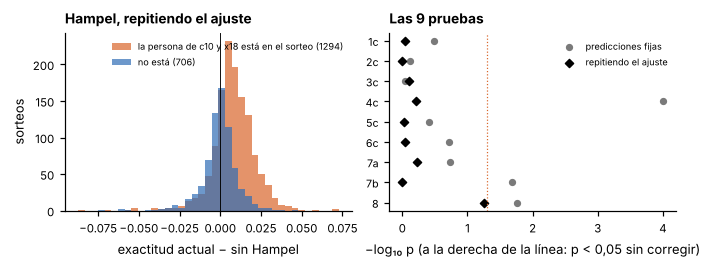

In [16]:
con_s23 = BOOT_R.muestra.apply(lambda m: SUJETO["c10"] in m).to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.5))
d4 = BOOT_R[NOMBRES[4]].to_numpy()
bins = np.linspace(np.nanmin(d4), np.nanmax(d4), 40)
axs[0].hist(d4[con_s23], bins=bins, color=APNEA, alpha=0.7, label=f"la persona de c10 y x18 está en el sorteo ({con_s23.sum()})")
axs[0].hist(d4[~con_s23], bins=bins, color=NORMAL, alpha=0.7, label=f"no está ({(~con_s23).sum()})")
axs[0].axvline(0, color="black", lw=0.6)
axs[0].set(xlabel="exactitud actual − sin Hampel", ylabel="sorteos", title="Hampel, repitiendo el ajuste")
axs[0].legend(fontsize=6)
y_ = np.arange(len(orden))[::-1]
axs[1].scatter(-np.log10(np.clip(comp.iloc[:, 1].to_numpy(), 1e-4, 1)), y_, color=GRIS, s=14, label="predicciones fijas")
axs[1].scatter(-np.log10(np.clip(comp.iloc[:, 2].to_numpy(), 1e-4, 1)), y_, color="black", s=14, marker="D", label="repitiendo el ajuste")
axs[1].axvline(-np.log10(0.05), color=APNEA, ls=":", lw=0.8)
axs[1].set_yticks(y_); axs[1].set_yticklabels([k.split(" · ")[0] for k in orden], fontsize=7)
axs[1].set(xlabel="−log₁₀ p (a la derecha de la línea: p < 0,05 sin corregir)", title="Las 9 pruebas")
axs[1].legend(fontsize=6)
fig.tight_layout()
save(fig, "07_p_reajuste")
print(f"Hampel: diferencia media {np.nanmean(d4[con_s23]):+.4f} con la persona en el sorteo, {np.nanmean(d4[~con_s23]):+.4f} sin ella")

**Qué se ve.**
- **Repitiendo el ajuste, ninguna de las 9 pruebas da p < 0,05, ni siquiera sin corregir por Holm.**
- **Hampel** pasa de p < 0,001 a p = 0,61. La figura muestra por qué: la diferencia es positiva casi solo en los sorteos que incluyen a la persona de c10 y x18.
- **La confianza** (p = 0,056) y el efecto de la exclusión sobre el ajuste (7b) tampoco se sostienen.

**Decisión corregida.** Se aplica la misma regla con los valores p corregidos. La única etapa que se mantiene es el refinamiento del pico R, por la condición (b), que no depende de la validación cruzada.

In [17]:
MANTENER_R = {k: any(v.values()) for k, v in CUMPLE_R.items()}
pd.DataFrame([{"etapa": f"{k} · {ETAPAS[k]}",
               "decisión registrada": "se mantiene" if MANTENER[k] else "se reemplaza",
               "condiciones que cumple (p corregido)": ", ".join(c for c, ok in CUMPLE_R[k].items() if ok) or "ninguna",
               "decisión final": "se mantiene" if MANTENER_R[k] else f"se reemplaza: {SIMPLE[k]}"} for k in ETAPAS]).set_index("etapa")

,decisión registrada,condiciones que cumple (p corregido),decisión final
etapa,,,
1 · Refinamiento del pico R,se mantiene,b,se mantiene
2 · Wiener en la EDR,se reemplaza,ninguna,se reemplaza: sin Wiener
3 · Excluir ectópicos de la EDR,se reemplaza,ninguna,se reemplaza: sin excluirlos
4 · Hampel en la EDR,se mantiene,ninguna,se reemplaza: sin Hampel
5 · Spline cúbico,se reemplaza,ninguna,se reemplaza: interpolación lineal
6 · Quitar la recta en Welch,se reemplaza,ninguna,se reemplaza: quitar la media
7 · Excluir minutos con > 20 % de RR corregidos,se reemplaza,ninguna,se reemplaza: clasificar todos los minutos
8 · Confianza según el movimiento,se reemplaza,ninguna,se reemplaza: no informarla


## 8. El detector simplificado final

Se quitan juntas las etapas que no cumplen ninguna condición con el p corregido. El chequeo de la combinación (simplificado contra actual) también se hace repitiendo el ajuste en cada sorteo.

In [18]:
QUITADAS, r_sim = combinar(CUMPLE_R, FAM_R, PERSONAS, SORTEOS, r_act, mostrar=True, n_reajuste=B_REAJUSTE)
T_SIM = tabla_comb(QUITADAS)
print("etapas que se mantienen:", [ETAPAS[k] for k in ETAPAS if k not in QUITADAS])

etapas quitadas [2, 3, 4, 5, 6, 7, 8]: actual − simplificado = +0.0134 (IC 95 % -0.0530 a +0.0441), p = 0.991, 22772 minutos comunes → no es peor
etapas que se mantienen: ['Refinamiento del pico R']


**Qué se ve.** Se mantiene solo el refinamiento del pico R. Quitar las otras siete etapas a la vez no empeora de forma demostrable: la diferencia de exactitud es +0,013 a favor del actual, pero repitiendo el ajuste el intervalo va de −0,053 a +0,044 (p = 0,99).

## 9. El filtro de Wiener en detalle: qué aporta y qué no

El Wiener es un tema obligatorio de la consigna y el paso más elaborado de la EDR. Por eso, además de la prueba de la sección 7, se reúne acá todo lo que se sabe de su efecto.

**Qué le hace a cada latido.** Se calcula H(f) en los 47 registros, y se compara la EDR de cada latido con y sin Wiener. El área del QRS es la suma de 13 muestras (±60 ms), así que ella misma es un filtro: responde casi solo a frecuencias bajas.

,min,25%,50%,75%,max
r latido a latido,0.859,0.983,0.998,1.000,1.000
"variación latido a latido, con / sin",0.297,0.673,0.884,0.948,1.045
H 0–1 Hz,0.099,0.473,0.759,0.866,0.950
H 1–5 Hz,0.305,0.815,0.902,0.957,0.979
H 5–10 Hz,0.225,0.910,0.959,0.985,0.993
H 10–25 Hz,0.173,0.915,0.964,0.975,0.987
H 25–40 Hz,0.023,0.585,0.727,0.854,0.898
H 40–50 Hz,0.003,0.051,0.324,0.485,0.684


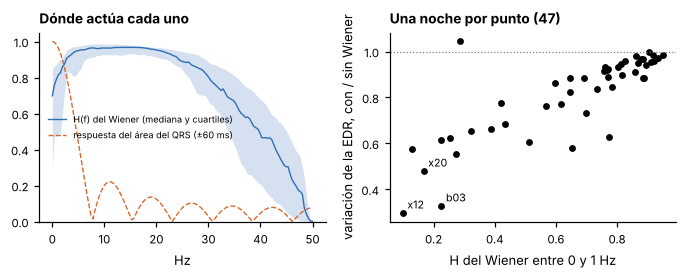

In [19]:
from src.preprocessing.wiener import estimate_psds, extract_realizations, wiener_from_beats
from src.features.edr import beat_edr
from src.qrs.beats import record_beats
from src.qrs.rr_clean import clean_rr
from src.config import QRS_AREA_HALF_S

BANDAS_W = {"0–1 Hz": (0, 1), "1–5 Hz": (1, 5), "5–10 Hz": (5, 10), "10–25 Hz": (10, 25), "25–40 Hz": (25, 40), "40–50 Hz": (40, 50.1)}


def wiener_registro(rec):
    ecg, fs = load_ecg(rec)
    t_r = record_beats(rec)["t_r"]
    x = apply_zero_phase(ecg, sos)
    f, ss, sn = estimate_psds(extract_realizations(x, t_r * fs, fs), fs)
    H = ss / (ss + sn)
    exc = np.r_[False, clean_rr(t_r)[2]]
    edr = {}
    for nom, pre in (("con", lambda s_: wiener_from_beats(s_, t_r, fs)), ("sin", None)):
        t, v = beat_edr(ecg, t_r, fs, "area", ECG_FILTER, exclude=exc, hampel=True, prefilter=pre, relative=True)
        edr[nom] = pd.Series(v, index=np.round(t, 3))
    m = pd.concat(edr, axis=1).dropna()
    var = m.groupby((m.index // 60).astype(int)).std().median()
    return {"record": rec, "f": f, "H": H, "r latido a latido": np.corrcoef(m.con, m.sin)[0, 1],
            "variación latido a latido, con / sin": var["con"] / var["sin"],
            **{f"H {k}": float(np.median(H[(f >= a) & (f < b)])) for k, (a, b) in BANDAS_W.items()}}


with ProcessPoolExecutor(4) as ex:
    WR = list(ex.map(wiener_registro, DEV))
tab_w = pd.DataFrame([{k: v for k, v in w.items() if k not in ("f", "H")} for w in WR]).set_index("record")
f_w = WR[0]["f"]; H_all = np.stack([w["H"] for w in WR])
N_AREA = int(round(2 * QRS_AREA_HALF_S * 100)) + 1
resp_area = np.abs(np.divide(np.sin(np.pi * f_w * N_AREA / 100), N_AREA * np.sin(np.pi * f_w / 100),
                             out=np.ones_like(f_w), where=f_w > 0))
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
axs[0].fill_between(f_w, *np.percentile(H_all, [25, 75], axis=0), color=NORMAL, alpha=0.2, lw=0)
axs[0].plot(f_w, np.median(H_all, axis=0), color=NORMAL, label="H(f) del Wiener (mediana y cuartiles)")
axs[0].plot(f_w, resp_area, color=APNEA, ls="--", label="respuesta del área del QRS (±60 ms)")
axs[0].set(xlabel="Hz", ylim=(0, 1.05), title="Dónde actúa cada uno")
axs[0].legend(fontsize=6)
axs[1].scatter(tab_w["H 0–1 Hz"], tab_w["variación latido a latido, con / sin"], s=12, color="black")
for rec in tab_w["variación latido a latido, con / sin"].nsmallest(3).index:
    axs[1].annotate(rec, (tab_w.loc[rec, "H 0–1 Hz"], tab_w.loc[rec, "variación latido a latido, con / sin"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
axs[1].axhline(1, color=GRIS, ls=":", lw=0.8)
axs[1].set(xlabel="H del Wiener entre 0 y 1 Hz", ylabel="variación de la EDR, con / sin Wiener", title="Una noche por punto (47)")
fig.tight_layout()
save(fig, "07_wiener")
tab_w.describe().loc[["min", "25%", "50%", "75%", "max"]].T.round(3)

**Qué se ve.**
- **Por encima de ~10 Hz el Wiener sobra.** Ahí atenúa el ruido muscular (H ~0,7 entre 25 y 40 Hz, ~0,3 entre 40 y 50 Hz), pero el área del QRS casi no responde a esas frecuencias: sumar 13 muestras ya promedia ese ruido. Las dos cosas hacen lo mismo.
- **Donde sí cambia la EDR es por debajo de ~5 Hz**, que es justo donde el área responde. Ahí H va de ~0,7 cerca de 0 Hz a ~0,9 en 5 Hz: lo que cambia de un latido a otro (la deriva de línea de base que sobrevive al filtro de 0,5 Hz, y la parte lenta de la forma del QRS) tiene en esas frecuencias tanta potencia como el latido promedio. El Wiener actúa como un pasaaltos suave extra y le saca a la EDR una parte de su variación latido a latido: un 12 % en la mediana de las noches y hasta un 70 % en algunas. En la mayoría de las noches la EDR casi no cambia (correlación latido a latido mediana 0,998).
- **No se sabe si lo que saca es ruido o respiración.** La deriva de línea de base es en parte respiratoria: es la base de otro método de EDR. Con los datos de desarrollo no se puede separar: el parecido con la respiración registrada no cambia de forma demostrable (`03` §6) y la detección tampoco (sección 7).

**Todo lo medido sobre el Wiener, junto:**

| Medida | Con Wiener contra sin Wiener | ¿Demostrable? |
|---|---|---|
| Coherencia con la respiración registrada, banda respiratoria (A1, `03` §6) | +0,009 | No (p de Holm 1,0) |
| Coherencia en la banda de la apnea (A2, `03` §6) | +0,003 | No (p de Holm 1,0) |
| AUC dentro de la noche (B, `03` §6) | +0,007 | No (p de Holm 1,0) |
| Exactitud del detector, validación cruzada (sección 3) | +0,006 (IC −0,024 a +0,041) | No (p 0,75 con predicciones fijas, 0,998 repitiendo el ajuste) |
| Sensibilidad / especificidad (sección 3) | +0,034 / −0,012 | Se compensan |
| Variación latido a latido de la EDR (arriba) | −12 % (mediana), hasta −70 % | Cambia la EDR, sin que se pueda decir si para bien |

**Qué cuesta.** Supone que la forma del latido es la misma toda la noche: en `x17` no lo es, y el filtro solo achica toda la señal (`03` §5). Agrega tres decisiones (largo del FIR, forma media o mediana, ventana de la realización), y su ganancia depende de la relación señal-ruido de cada noche.

**Qué hace la bibliografía.** Se buscó en PubMed Central, en el texto completo de los artículos de acceso abierto, con una consulta reproducible (`scripts/buscar_wiener_pmc.py`; resultados del 2026-11-20 en `docs/busqueda_wiener_pmc.json`):

| Conjunto | Artículos con texto completo | Mencionan "Wiener" | Para comparar: Butterworth / pasabanda / wavelet / filtro de mediana |
|---|---|---|---|
| Detección de apnea con ECG | 135 (56 usan la base Apnea-ECG) | **0** | 20 / 33 / 42 / 17 |
| Respiración derivada del ECG (EDR) | 47 | **0** con ECG (1 lo usa con sonidos traqueales) | 12 / 19 / 15 / 2 |

En PubMed, entre los 407 resúmenes de detección de apnea con ECG y los 170 de EDR, ninguno menciona Wiener. Los dos trabajos de referencia con esta base no son de acceso abierto, así que solo se pudieron leer sus resúmenes, que tampoco lo mencionan: Penzel et al. (2002), que comparan los 13 algoritmos del desafío de 2000, describen que los mejores usaron features espectrales del ritmo cardíaco y del efecto de la respiración sobre el ECG; de Chazal et al. (2003) usan features de los intervalos RR y de una EDR con discriminantes lineales y cuadráticos.

El Wiener estimado con realizaciones (Wiener *a posteriori*) viene de otro problema: mejorar el **promedio** de potenciales evocados (Walter, 1968) y del ECG de alta resolución promediado (Lander y Berbari, 1997). Allí lo que se quiere es la forma promedio, no la variación de un latido a otro, y aun así su beneficio fue discutido:
- Ungan y Başar (1976) mostraron que puede perder información cuando la respuesta no es estacionaria.
- Nagelkerke y Strackee (1979) concluyeron que solo se justifica como forma de introducir información previa.
- Möcks et al. (1986), con datos de 50 personas, encontraron que casi toda su mejora era una atenuación que dependía de la relación señal-ruido de cada persona, y que eso aumentaba artificialmente las diferencias entre personas (de Weerd, 1981, resume la controversia).

Lo último importa acá: en C la EDR se compara entre personas. Con la EDR relativa, una atenuación uniforme se cancela al dividir por el tamaño del QRS, pero la parte que depende de la frecuencia no.

**Conclusión sobre el Wiener.** Se implementa y se analiza, como pide la consigna (`03` §5–6 y esta sección). No entra en el detector por cuatro razones:
- no mejora de forma demostrable ninguna medida;
- en las frecuencias donde podría ayudar, el área del QRS ya promedia el ruido;
- donde cambia la EDR, no se sabe si saca ruido o respiración;
- ningún trabajo publicado de detección de apnea o de EDR con ECG lo usa.

## 10. Validación anidada del procedimiento corregido

Se repite la sección 6, ahora con el valor p corregido: en cada grupo externo se hace el bootstrap que repite el ajuste solo con las personas de adentro, con 500 sorteos para que el cálculo sea manejable (con 9 pruebas, el p más chico que se puede distinguir sigue alcanzando para que una prueba resista Holm).

In [20]:
B_ANIDADA = 500
filas_c, preds_c = [], []
for k_out, gpo in enumerate(grupos_personas(PERSONAS)):
    afuera = set(gpo)
    tr = [p for p in PERSONAS if p not in afuera]
    so = sorteos_personas(tr, n=len(SORTEOS), semilla=2026)
    fam_i, r_a_i, _, _ = pruebas_etapas(tr, so)
    bo_i = boot_reajuste(preparar_etapas(tr), est_etapas, tr, B_ANIDADA)
    fam_ri = {k: (fam_i[k][0], bo_i[k].to_numpy(), fam_i[k][2]) for k in fam_i}
    cumple_i, _ = decidir(fam_ri, tr, so)
    quitar_i, _ = combinar(cumple_i, fam_ri, tr, so, r_a_i, n_reajuste=B_ANIDADA)
    pred_i, w_i = ajustar_y_clasificar(quitar_i, tr, afuera)
    preds_c.append(pred_i.assign(grupo=k_out))
    filas_c.append({"grupo afuera": k_out + 1, "etapas que se mantienen": ", ".join(str(k) for k in ETAPAS if k not in quitar_i), "w": w_i})
r_anid = pd.concat(preds_c, ignore_index=True)
pd.DataFrame(filas_c).set_index("grupo afuera")

,etapas que se mantienen,w
grupo afuera,,
1,1,1.50
2,1,0.50
3,1,1.00
4,1,1.25
5,1,1.00


**Qué se ve.** Con el p corregido, en los 5 grupos externos el procedimiento toma la misma decisión que con todas las personas: mantener solo el refinamiento del pico R. La decisión ya no depende de qué personas se usan. Por eso la validación anidada da lo mismo que la simple (sección 11): elegir las etapas con los mismos datos ya no agrega optimismo.

## 11. El detector actual y el simplificado, lado a lado

Todas las medidas son de validación cruzada en desarrollo, y son **descriptivas**. P1, P2 y P3 se calculan como en `04` §14, pero no prueban la hipótesis, porque la hipótesis se armó con estos datos. La última columna es la estimación sin el optimismo de elegir las etapas con los mismos datos.

In [21]:
def resumen(t, r, nombre):
    den = [auc(g.P_RR, g.label) for _, g in r.groupby("record")
           if min((g.label == 1).sum(), (g.label == 0).sum()) >= MIN_MINUTES_PER_CLASS]
    nn = r.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"), EDR_noche=("EDR_noche", "first"))
    nn["categoria"] = nn.index.map(CATEGORIA)
    con_etiqueta = (t.label >= 0) & np.isfinite(t.P_RR)
    fila = {"detector": nombre, **metricas(r.label, r.pred),
            "P1 · AUC dentro de la noche del RR": float(np.mean(den)),
            "P2 · ρ nivel EDR vs % de apnea": spearmanr(nn.EDR_noche, nn.real)[0],
            "ρ por noche": spearmanr(nn.real, nn.est)[0],
            "% marcado en controles": 100 * nn[nn.categoria == "C"].est.mean(),
            "% de minutos con etiqueta que clasifica": 100 * len(r) / int(con_etiqueta.sum())}
    if "margen" in r:
        fila["AUC con personas no vistas"] = float(np.nanmean([auc(g.margen, g.label) for _, g in r.groupby("grupo")]))
        fila["P3 · AUC de C (márgenes de la validación cruzada)"] = auc(r.margen, r.label)
    return fila


lado = pd.DataFrame([resumen(T_ACT, r_act, "actual (evaluada en test)"),
                     resumen(T_SIM, r_sim, "simplificado (validación simple)"),
                     resumen(T_SIM, r_anid, "procedimiento completo (validación anidada)")]).set_index("detector").T
d_n, boot_n, n_n = comparar(r_act, r_anid, SORTEOS)
print(f"exactitud actual − procedimiento anidado, sobre {n_n} minutos comunes: {d_n:+.4f} "
      f"(IC 95 % {np.nanpercentile(boot_n, 2.5):+.4f} a {np.nanpercentile(boot_n, 97.5):+.4f}), p = {p_bootstrap(boot_n):.3f}")
lado.round(3)

exactitud actual − procedimiento anidado, sobre 22772 minutos comunes: +0.0134 (IC 95 % -0.0105 a +0.0405), p = 0.302


detector,actual (evaluada en test),simplificado (validación simple),procedimiento completo (validación anidada)
sensibilidad,0.814,0.802,0.802
especificidad,0.851,0.834,0.834
exactitud,0.836,0.821,0.821
P1 · AUC dentro de la noche del RR,0.908,0.906,0.906
P2 · ρ nivel EDR vs % de apnea,0.825,0.778,0.778
ρ por noche,0.795,0.760,0.760
% marcado en controles,7.376,12.098,12.098
% de minutos con etiqueta que clasifica,99.411,100.000,100.000
AUC con personas no vistas,0.907,0.887,NaN
P3 · AUC de C (márgenes de la validación cruzada),0.920,0.899,NaN


PosixPath('/home/user/TP-PSB-G8/informe/figuras/07_actual_vs_simplificado.png')

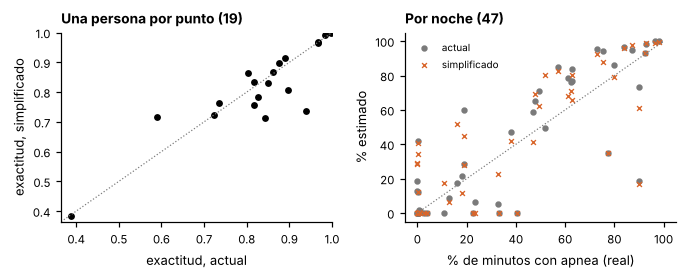

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
pa = r_act.assign(ok=r_act.pred == r_act.label).groupby("subject").ok.mean()
ps = r_sim.assign(ok=r_sim.pred == r_sim.label).groupby("subject").ok.mean()
axs[0].scatter(pa, ps.reindex(pa.index), s=12, color="black")
lim = [min(pa.min(), ps.min()) - 0.02, 1]
axs[0].plot(lim, lim, color=GRIS, ls=":", lw=0.8)
axs[0].set(xlabel="exactitud, actual", ylabel="exactitud, simplificado", title="Una persona por punto (19)", xlim=lim, ylim=lim)
na = r_act.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
ns = r_sim.groupby("record").agg(real=("label", "mean"), est=("pred", "mean"))
axs[1].scatter(100 * na.real, 100 * na.est, s=10, color=GRIS, label="actual")
axs[1].scatter(100 * ns.real, 100 * ns.est, s=10, color=APNEA, marker="x", label="simplificado")
axs[1].plot([0, 100], [0, 100], color=GRIS, ls=":", lw=0.8)
axs[1].set(xlabel="% de minutos con apnea (real)", ylabel="% estimado", title="Por noche (47)")
axs[1].legend(fontsize=6.5)
fig.tight_layout()
save(fig, "07_actual_vs_simplificado")

**Qué se ve.**
- **Ninguna diferencia es demostrable.** La exactitud del simplificado es 0,821 contra 0,836 del actual: la diferencia actual − simplificado es +0,013 (IC −0,011 a +0,041 con predicciones fijas, y más ancho repitiendo el ajuste: −0,053 a +0,044).
- **Pero el simplificado es algo peor en varias medidas descriptivas.** Marca más minutos en los controles (12,1 % contra 7,4 %), ordena algo peor las noches (ρ 0,76 contra 0,80), su AUC con personas no vistas es más bajo (0,89 contra 0,91) y P2 baja (0,78 contra 0,83).
- **Casi todo viene de sacar Hampel.** Sin Hampel, las dos noches de control de una misma persona (c10 y x18) tienen un nivel de EDR inflado y se marcan como apnea (sección 4).
- **Esto es lo que hace la regla de sencillez con 19 personas.** Un efecto concentrado en una sola persona no se puede distinguir del azar, así que la etapa no entra, aunque descriptivamente ayude. Es una limitación del tamaño de la muestra, y se informa como tal.

## 12. Los parámetros del detector simplificado

Se ajustan con todos los minutos de desarrollo, igual que en `04` §7 y §14: w es el que maximiza el AUC (de 0 a 3, cada 0,25) y el umbral es el de Youden. Se guardan en `docs/parametros_simplificado.json` junto con la configuración de las etapas. **Este detector no se evaluó en test.**

In [23]:
mc = None if 7 in QUITADAS else MINUTE_MAX_CORRECTED
e_sim = con_ev(T_SIM, mc)
w_sim = float(GRILLA_W[int(np.argmax([auc(c_score(e_sim, fit_c(e_sim, w, max_corrected=mc)), e_sim.label) for w in GRILLA_W]))])
p_sim = fit_c(e_sim, w_sim, max_corrected=mc)
u_sim = youden_threshold(c_score(e_sim, p_sim).to_numpy(), e_sim.label.to_numpy())
etapas_cfg = {"refinamiento_pico_r": 1 not in QUITADAS, "wiener_edr": 2 not in QUITADAS,
              "excluir_ectopicos_edr": 3 not in QUITADAS, "hampel_edr": 4 not in QUITADAS,
              "interpolacion": "cubic" if 5 not in QUITADAS else "linear",
              "tendencia_welch": "linear" if 6 not in QUITADAS else "constant",
              "max_rr_corregidos_por_minuto": MINUTE_MAX_CORRECTED if 7 not in QUITADAS else None,
              "confianza": 8 not in QUITADAS}
if 8 not in QUITADAS:
    etapas_cfg["cortes_confianza_mov_rel"] = [float(c) for c in np.quantile(e_sim.mov_rel, (0.5, 0.9))]
PARAMS_SIM = {"feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
              **{k: p_sim[k] for k in ("mu1", "s1", "mu2", "s2", "w")}, "umbral": u_sim,
              "banda_hz": list(BAND), "ventana_s": WINDOW_S, "etapas": etapas_cfg,
              "fijado_con": "47 registros de desarrollo (notebooks/07_simplificacion.ipynb)",
              "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente"}
save_params(ROOT / "docs" / "parametros_simplificado.json", PARAMS_SIM)
print(json.dumps(PARAMS_SIM, indent=2, ensure_ascii=False))

{
  "feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
  "mu1": -1.4934964914174096,
  "s1": 0.5952056650946452,
  "mu2": -1.9835453429591907,
  "s2": 0.6086845803875878,
  "w": 1.0,
  "umbral": 0.4388201887615375,
  "banda_hz": [
    0.01,
    0.05
  ],
  "ventana_s": 240,
  "etapas": {
    "refinamiento_pico_r": true,
    "wiener_edr": false,
    "excluir_ectopicos_edr": false,
    "hampel_edr": false,
    "interpolacion": "linear",
    "tendencia_welch": "constant",
    "max_rr_corregidos_por_minuto": null,
    "confianza": false
  },
  "fijado_con": "47 registros de desarrollo (notebooks/07_simplificacion.ipynb)",
  "evaluacion": "solo validación cruzada por personas en desarrollo; sin evaluación independiente"
}


## 13. Conclusión

| Etapa | Decisión | Por qué |
|---|---|---|
| 1 · Refinamiento del pico R | Se mantiene | (b): el desacuerdo entre las dos fases baja de 10,0 a 2,3 ms, en los 47 registros |
| 2 · Wiener en la EDR | Sale (se implementa y se analiza en `03` y en la sección 9) | No mejora ninguna medida de forma demostrable; donde podría ayudar, el área del QRS ya promedia el ruido; ningún trabajo publicado de este tipo lo usa |
| 3 · Excluir ectópicos de la EDR | Sale | No mejora la EDR ni el detector |
| 4 · Hampel en la EDR | Sale | Su efecto viene de una sola persona; repitiendo el ajuste, p = 0,61 |
| 5 · Spline cúbico | Sale: interpolación lineal | No cambia el detector |
| 6 · Quitar la recta en Welch | Sale: se quita la media | Con la ventana de Hann, la media no llega a la banda; la recta no cambia el detector |
| 7 · Excluir minutos con > 20 % de RR corregidos | Sale: se clasifican todos | En los 135 minutos que se excluirían (0,6 %) el detector acierta menos (0,64), pero son muy pocos para demostrarlo |
| 8 · Confianza según el movimiento | Sale | La exactitud baja con el movimiento (0,86 a 0,76), pero repitiendo el ajuste no es demostrable (p = 0,056) |

- **El detector simplificado** tiene una sola etapa extra (el refinamiento del pico R) además de las imprescindibles. Sus parámetros están en `docs/parametros_simplificado.json`. En validación cruzada en desarrollo su exactitud es 0,821; no tiene una evaluación independiente.
- **El detector evaluado en test** sigue siendo el de `docs/parametros_test.json`, con las ocho etapas. Su evaluación única en test (`05`) sigue siendo válida para esa versión y no se atribuye a la simplificada.
- **Dos agregados al criterio corrigieron dos errores de validación que el criterio registrado no evitaba:** medir con los mismos datos con que se eligió (validación anidada) y un valor p que ignoraba el ajuste (bootstrap que repite el ajuste). Los dos quedaron anotados en `docs/criterio_parsimonia.md`.